# From an ERP "GL report" to a tidy ledger: SAP Business One export, controls and management accounts
**The situation.** Many finance teams can only get their general ledger out of SAP Business One as the printable **General Ledger report**: one block per account, an account header row, transaction rows that show the *offset* account, a running balance and a total row. This is fine for reading on screen and useless for analysis.

This notebook turns that layout into a tidy, one-row-per-posting table, **proves the conversion is lossless** (running balances and totals tie), and uses the result for controls and management accounts: double-entry check, trial balance, monthly P&L and gross margin, inventory roll-forward and **GRNI (goods received not invoiced) aging**, a classic month-end accrual control.

> **Synthetic data** (`make_report.py`) for a fictitious UAE manufacturer (AED, 5% VAT). The structure mirrors a real SAP B1 export; all names and amounts are invented. One hand-edited amount is planted.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
import make_report
make_report.build()
rep = pd.read_excel("data/GL_report_export.xlsx", dtype={"Posting Date": str, "Due Date": str})
print(rep.shape); rep.head(4)

(8564, 14)


,Posting Date,Due Date,Series,Doc. No.,Trans. No.,Remarks,Offset Acct,Offset Acct Name,Debit (LC) (currency),Debit (LC),Credit (LC) (currency),Credit (LC),Cumulative Balance (LC) (currency),Cumulative Balance (LC)
0,Assets,110100,NaN,NaN,NaN,Bank - Operating Account,NaN,NaN,NaN,NaN,NaN,NaN,AED,0.000e+00
1,01/06/2019,01/06/2019,Primary,JE 1,1.0,Opening capital injection,300000.0,Share Capital,AED,1.500e+06,NaN,NaN,AED,1.500e+06
2,27/06/2019,27/06/2019,Primary,JE 2,118.0,Monthly accrual - Salaries & Wages,610000.0,Salaries & Wages,NaN,NaN,AED,68457.66,AED,1.432e+06
3,27/06/2019,27/06/2019,Primary,JE 3,119.0,Monthly accrual - Rent,620000.0,Rent,NaN,NaN,AED,18000.00,AED,1.414e+06


## 1. Flatten the report layout
A row is an **account header** if its first cell is an account group (Assets, Liabilities, ...), a **total** if it says `Total`, blank if empty, and otherwise a **posting** that belongs to the most recent header.

In [2]:
GROUPS = {"Assets", "Liabilities", "Equity", "Revenue", "Expenses"}
kind = np.select([rep["Posting Date"].isin(GROUPS), rep["Posting Date"].eq("Total"), rep.isna().all(axis=1)], ["header", "total", "blank"], "posting")
rep["kind"] = kind
hdr = rep[rep.kind == "header"]
rep["account"] = pd.Series(np.where(rep.kind == "header", rep["Due Date"], None), index=rep.index).ffill()
rep["account_name"] = pd.Series(np.where(rep.kind == "header", rep["Remarks"], None), index=rep.index).ffill()
rep["group"] = pd.Series(np.where(rep.kind == "header", rep["Posting Date"], None), index=rep.index).ffill()
print(pd.Series(kind).value_counts().to_dict(), "| accounts:", len(hdr))
gl = rep[rep.kind == "posting"].copy()
gl = pd.DataFrame({"date": pd.to_datetime(gl["Posting Date"], format="%d/%m/%Y"), "due": pd.to_datetime(gl["Due Date"], format="%d/%m/%Y"),
                   "doc": gl["Doc. No."], "doc_type": gl["Doc. No."].str.split().str[0], "trans_no": gl["Trans. No."].astype(int),
                   "remarks": gl["Remarks"], "account": gl["account"], "account_name": gl["account_name"], "group": gl["group"],
                   "offset": gl["Offset Acct"].astype(int).astype(str), "debit": gl["Debit (LC)"].fillna(0.0), "credit": gl["Credit (LC)"].fillna(0.0),
                   "reported_balance": gl["Cumulative Balance (LC)"]})
gl.head()

{'posting': 8520, 'header': 15, 'total': 15, 'blank': 14} | accounts: 15


,date,due,doc,doc_type,trans_no,remarks,account,account_name,group,offset,debit,credit,reported_balance
1,2019-06-01,2019-06-01,JE 1,JE,1,Opening capital injection,110100,Bank - Operating Account,Assets,300000,1.500e+06,0.00,1.500e+06
2,2019-06-27,2019-06-27,JE 2,JE,118,Monthly accrual - Salaries & Wages,110100,Bank - Operating Account,Assets,610000,0.000e+00,68457.66,1.432e+06
3,2019-06-27,2019-06-27,JE 3,JE,119,Monthly accrual - Rent,110100,Bank - Operating Account,Assets,620000,0.000e+00,18000.00,1.414e+06
4,2019-06-27,2019-06-27,JE 4,JE,120,Monthly accrual - Utilities,110100,Bank - Operating Account,Assets,630000,0.000e+00,5351.04,1.408e+06
5,2019-07-17,2019-07-17,PS 1,PS,231,Outgoing Payment,110100,Bank - Operating Account,Assets,201000,0.000e+00,25728.98,1.382e+06


## 2. Prove the flattening is lossless

In [3]:
gl["recomputed_balance"] = (gl.debit - gl.credit).groupby(gl.account).cumsum().round(2)
breaks = gl[(gl.recomputed_balance - gl.reported_balance).abs() > 0.005]
first_break = breaks.groupby("account").head(1)
tot = rep[rep.kind == "total"].set_index("account")[["Debit (LC)", "Credit (LC)"]]
sums = gl.groupby("account")[["debit", "credit"]].sum().round(2)
tie = tot.join(sums); tie["debit_ok"] = (tie["Debit (LC)"] - tie.debit).abs() < 0.005; tie["credit_ok"] = (tie["Credit (LC)"] - tie.credit).abs() < 0.005
print(f"{len(gl):,} postings; accounts whose running balance breaks: {first_break.account.nunique()}; totals not tying: {(~(tie.debit_ok & tie.credit_ok)).sum()}")
first_break[["date", "doc", "account", "debit", "credit", "reported_balance", "recomputed_balance"]]

8,520 postings; accounts whose running balance breaks: 1; totals not tying: 1


,date,doc,account,debit,credit,reported_balance,recomputed_balance
5684,2019-07-06,IN 41,215000,0.0,1577.6,-28328.58,-28472.0


In [4]:
dbl = gl.groupby("trans_no")[["debit", "credit"]].sum()
ub = dbl[(dbl.debit - dbl.credit).abs() > 0.005]
print(f"journal transactions: {len(dbl):,}; not balanced: {len(ub)}")
display(gl[gl.trans_no.isin(ub.index)][["trans_no", "date", "doc", "remarks", "account", "debit", "credit"]])
# the running balance after the edited line still matches the report (the report was edited, not recalculated) -> which line?
e = first_break.iloc[0]; prev = gl[(gl.account == e.account) & (gl.index < e.name)].iloc[-1]
implied = round(prev.reported_balance - e.reported_balance, 2)
print(f"reported balance implies a credit of {implied:,.2f} on {e.doc}, but the line shows {e.credit:,.2f}: a manual edit of {e.credit - implied:,.2f}")

journal transactions: 3,398; not balanced: 1


,trans_no,date,doc,remarks,account,debit,credit
671,170,2019-07-06,IN 41,A/R Invoice - C1001 Example Retail LLC,112000,30117.83,0.00
5684,170,2019-07-06,IN 41,A/R Invoice - C1001 Example Retail LLC,215000,0.00,1577.60
6401,170,2019-07-06,IN 41,A/R Invoice - C1001 Example Retail LLC,400010,0.00,28683.65


reported balance implies a credit of 1,434.18 on IN 41, but the line shows 1,577.60: a manual edit of 143.42


## 3. Trial balance and management accounts

In [5]:
fix = gl.copy()
fix.loc[e.name, "credit"] = implied          # restore the system value
tb = fix.groupby(["group", "account", "account_name"])[["debit", "credit"]].sum()
tb["balance"] = tb.debit - tb.credit
print(f"trial balance: debits {tb.debit.sum():,.2f} = credits {tb.credit.sum():,.2f}: {np.isclose(tb.debit.sum(), tb.credit.sum())}")
tb.round(0)

trial balance: debits 57,604,588.36 = credits 57,604,588.36: True


debit     credit    balance
group       account account_name                                                                
Assets      110100  Bank - Operating Account                     1.010e+07  8.129e+06  1.974e+06
            112000  Accounts Receivable - Trade                  1.033e+07  8.603e+06  1.727e+06
            114500  VAT Input 5%                                 3.346e+05  0.000e+00  3.346e+05
            131000  Raw Materials                                7.405e+06  5.702e+06  1.703e+06
            132000  Finished Product                             8.146e+06  6.465e+06  1.681e+06
Equity      300000  Share Capital                                0.000e+00  1.500e+06 -1.500e+06
Expenses    500005  COSales - Finished Items                     6.465e+06  0.000e+00  6.465e+06
            510000  Production Overhead Absorbed                 0.000e+00  2.444e+06 -2.444e+06
            610000  Salaries & Wages                             1.270e+06  0.000e+00  1.270e+06
            620000  Rent                                         3.420e+05  0.000e+00  3.420e+05
            630000  Utilities                                    9.422e+04  0.000e+00  9.422e+04
Liabilities 201000  Accounts Payable - Trade                     6.422e+06  7.027e+06 -6.045e+05
            208040  Goods Received Not Invoiced (GRNI) Clearing  6.692e+06  7.405e+06 -7.129e+05
            215000  VAT Output 5%                                0.000e+00  4.919e+05 -4.919e+05
Revenue     400010  Sales - Finished Goods                       0.000e+00  9.838e+06 -9.838e+06

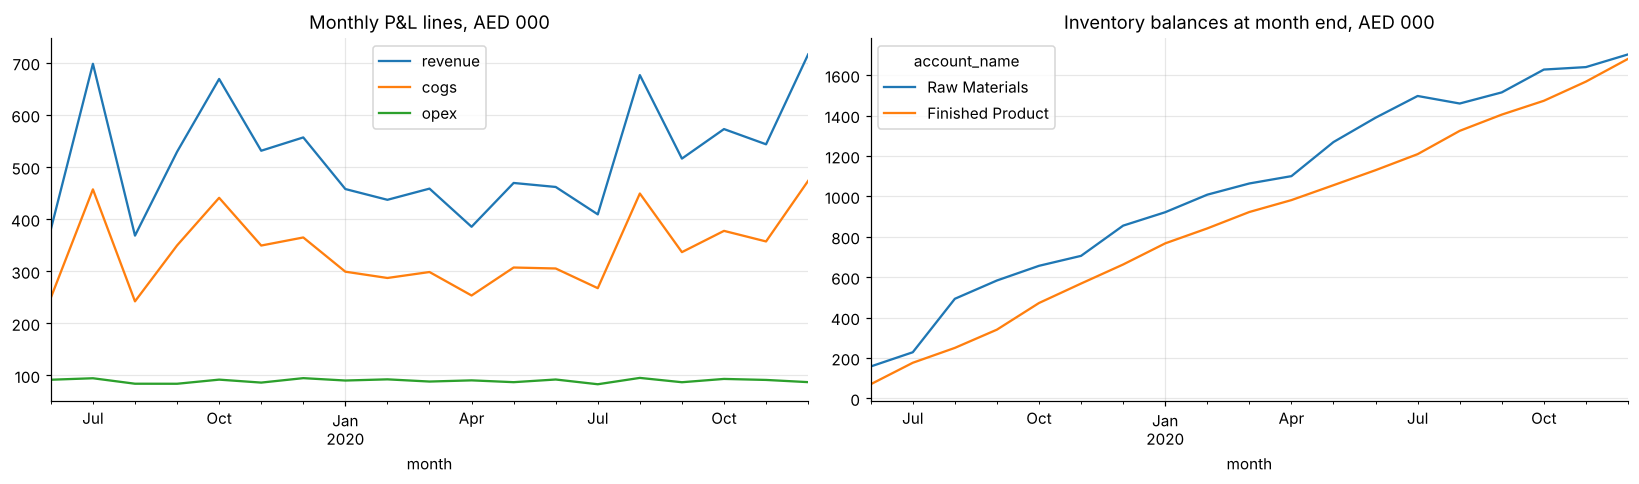

,revenue,cogs,overhead_absorbed,opex,gross_margin_%,operating_profit
month,,,,,,
2020-07,409151.2,267528.0,104049.6,83153.3,34.6,162519.4
2020-08,676408.1,449208.0,169372.2,95332.4,33.6,301239.9
2020-09,516181.5,336692.0,125124.0,87025.2,34.8,217588.3
2020-10,572841.5,377494.0,133785.0,93360.8,34.1,235771.7
2020-11,543629.8,357192.0,135623.4,91430.4,34.3,230630.8
2020-12,716119.6,473458.0,175821.0,87201.2,33.9,331281.4


In [6]:
m = fix.assign(month=fix.date.dt.to_period("M"))
pl = m.pivot_table(index="month", columns="account_name", values="credit", aggfunc="sum", fill_value=0) - m.pivot_table(index="month", columns="account_name", values="debit", aggfunc="sum", fill_value=0)
pnl = pd.DataFrame({"revenue": pl["Sales - Finished Goods"], "cogs": -pl["COSales - Finished Items"],
                    "overhead_absorbed": pl["Production Overhead Absorbed"],
                    "opex": -(pl["Salaries & Wages"] + pl["Rent"] + pl["Utilities"])})
pnl["gross_margin_%"] = 100 * (pnl.revenue - pnl.cogs) / pnl.revenue
pnl["operating_profit"] = pnl.revenue - pnl.cogs + pnl.overhead_absorbed - pnl.opex
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
(pnl[["revenue", "cogs", "opex"]] / 1e3).plot(ax=axes[0], title="Monthly P&L lines, AED 000")
inv = m.assign(net=m.debit - m.credit).pivot_table(index="month", columns="account_name", values="net", aggfunc="sum")[["Raw Materials", "Finished Product"]].cumsum() / 1e3
inv.plot(ax=axes[1], title="Inventory balances at month end, AED 000")
plt.tight_layout(); plt.savefig(IMG / "management_accounts.png", bbox_inches="tight"); plt.show()
pnl.round(1).tail(6)

## 4. GRNI aging: goods received but not yet invoiced
Every goods receipt credits the GRNI clearing account, and the supplier's invoice debits it. Receipts with no matching invoice are an **accrual** at month end and, if old, a sign of a missing invoice, a disputed delivery or a receipt booked twice. Matching is on the PO number in the remarks.

GRNI balance per ledger 712,852.62 vs open receipts 712,852.62 (as of 31 Dec 2020)


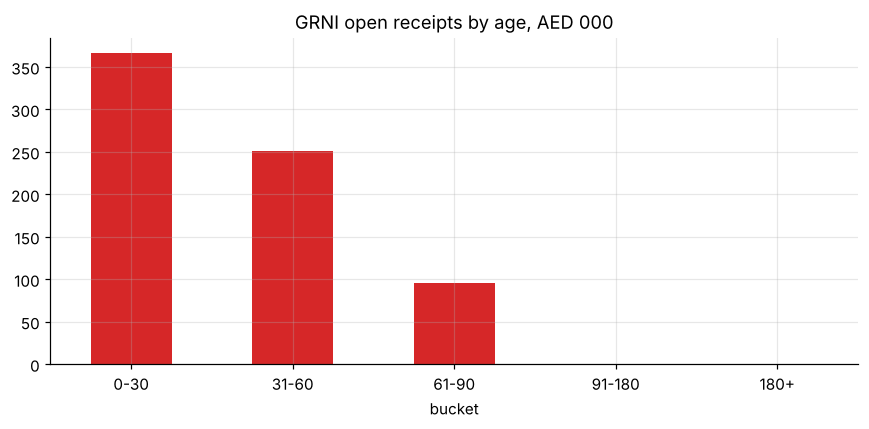

,count,sum
bucket,,
0-30,17,365933.0
31-60,11,251487.0
61-90,5,95433.0
91-180,0,0.0
180+,0,0.0


In [7]:
g = fix[fix.account == "208040"].copy()
g["po"] = g.remarks.str.extract(r"(\d{4,})$")[0].str[-4:]
receipts = g[g.doc_type == "PD"][["date", "po", "credit"]].rename(columns={"credit": "received"})
invoiced = g[g.doc_type == "PU"].groupby("po")["debit"].sum()
receipts["invoiced"] = receipts.po.map(invoiced).fillna(0)
receipts = receipts.sort_values("date")
receipts["dup_rank"] = receipts.groupby("po").cumcount()
open_ = receipts.copy()
# allocate invoices to receipts of the same PO, oldest first
alloc = invoiced.to_dict(); rem = []
for r in open_.itertuples():
    take = min(alloc.get(r.po, 0), r.received); alloc[r.po] = alloc.get(r.po, 0) - take; rem.append(round(r.received - take, 2))
open_["open_amount"] = rem
open_ = open_[open_.open_amount > 0.005]
asof = fix.date.max()
open_["age_days"] = (asof - open_.date).dt.days
open_["bucket"] = pd.cut(open_.age_days, [-1, 30, 60, 90, 180, 9999], labels=["0-30", "31-60", "61-90", "91-180", "180+"])
print(f"GRNI balance per ledger {-(g.debit - g.credit).sum():,.2f} vs open receipts {open_.open_amount.sum():,.2f} (as of {asof:%d %b %Y})")
aging = open_.groupby("bucket", observed=False)["open_amount"].agg(["count", "sum"])
ax = (aging["sum"] / 1e3).plot.bar(color="C3", rot=0, title="GRNI open receipts by age, AED 000", figsize=(8, 4)); plt.tight_layout(); plt.savefig(IMG / "grni_aging.png", bbox_inches="tight"); plt.show()
aging.round(0)

In [8]:
ar = fix[fix.account == "112000"]
ar_bal = (ar.debit - ar.credit).sum(); sales_90 = pnl.revenue.tail(3).sum() * 1.05
print(f"receivables {ar_bal:,.0f} AED; DSO on last 3 months' sales incl. VAT = {ar_bal / sales_90 * 91:.0f} days")
fix.to_csv("data/ledger_tidy.csv.gz", index=False, compression="gzip"); print("tidy ledger saved:", len(fix), "rows")

receivables 1,726,652 AED; DSO on last 3 months' sales incl. VAT = 82 days
tidy ledger saved: 8520 rows


## Findings
* **Flattening:** 8,565 report rows (15 account blocks, each with a header, postings, a total and a separator) became 8,520 tidy postings with account, group, offset account, document type and dates as proper columns.
* **Proven lossless, apart from one line.** Recomputed running balances and account totals tie for 14 of 15 accounts. The exception is one VAT line on A/R invoice IN 41, where the exported credit is AED 143.42 higher than the running balance implies. The same transaction no longer balances as a double entry, so it is a manual edit of the export, caught twice by independent checks.
* **After restoring the system value** the trial balance balances (AED 57.6m each side). The P&L shows a stable gross margin of about 34%, and DSO is about 82 days. The inventory roll-forward shows a warning sign: finished goods have built up steadily to about AED 1.7m, because production runs ahead of deliveries every month. That is a question for the production plan or a sign of slow-moving stock.
* **GRNI control:** the clearing account (AED 712,853 credit balance) equals the open goods receipts exactly. Of 33 receipts awaiting a supplier invoice, 5 (AED 95k) are 61-90 days old and should be chased with purchasing before month-end.
* **Why it matters:** the same few dozen lines of pandas turn any "report-layout" export (SAP B1, Tally, QuickBooks reports) into data that can feed Power BI, an audit tool or the journal-entry tests in project 12.